## Evaluating parameter estimation results

A finished parameter estimation is a point in parameter space together with a set of diagnostics. The objective value says how close the simulation is to the measurements. The correlation matrix and the Fisher information matrix say whether that point is tightly determined, or whether other parameter values would fit the same data.

This notebook uses the bundled `schaber` example: the small signal-transduction model from the supplement of Schaber and Klipp (2011), with a fit already stored in the file. The calculations recompute the statistics of that stored solution and read them back.


## Setup


In [1]:
import sys
if '../..' not in sys.path:
    sys.path.append('../..')

from basico import *
import numpy as np
import pandas as pd
%matplotlib inline

pd.set_option('display.float_format', lambda x: f'{x:.6g}')


## The model and the data

`load_example('schaber')` opens the COPASI file shipped with basiCO. A signal `S` decays, and while it is present it activates the conversion of `T` into `Tp`. `Tp` converts back to `T`. The measured quantity is the assignment species `TpFit`, defined as `[Tp] / 0.5`.

Two local kinetic parameters are estimated: `(v1).k`, the rate constant of the activation, and `(v2).k1`, the rate constant of the back-reaction. The decay rate of `S` stays fixed.


In [2]:
load_example('schaber')


<CDataModel "Root">

In [3]:
get_fit_parameters()


,lower,upper,start,affected,cn
name,,,,,
(v1).k,0,100,2.26794,[],"CN=Root,Model=Schaber Example,Vector=Reactions..."
(v2).k1,0,100,1.42521,[],"CN=Root,Model=Schaber Example,Vector=Reactions..."


An empty `affected` list means the parameter is used in every experiment. One time course, `Data set 1`, is mapped to `[TpFit]`. The experiment uses mean-square weighting, so the objective is the sum of squared residuals and each point contributes with equal weight.


In [4]:
get_data_from_experiment('Data set 1')


,Time,[TpFit]
0,1,1
1,2,0.88
2,4,0.39
3,6,0.22


## Statistics of the stored solution

`run_parameter_estimation(method=PE.CURRENT_SOLUTION)` evaluates the objective and the parameter sensitivities at the parameter values already stored in the file, and leaves those values unchanged. Use it when a file already contains a fit and the goal is to inspect that fit. The returned table is the solution: bounds, value, and the experiments each parameter applies to.

The example file also contains other COPASI tasks. Initializing them can print warnings about the scan, optimization, Lyapunov exponents, or linear noise approximation. Those messages come from those tasks; the parameter estimation result is unaffected.


In [5]:
run_parameter_estimation(method=PE.CURRENT_SOLUTION)


Uncaptured Errors: >WARNING 2026-10-24T14:14:40<
  There is nothing to scan.>ERROR 2026-10-24T14:14:40<
  Optimization (6): No adjustable Parameters specified.>ERROR 2026-10-24T14:14:40<
  CLyapMethod (3): Only 2 exponents can be calculated for this model because the model has only 2 independent variables.>ERROR 2026-10-24T14:14:40<
  TSSA can not be applyed for systems with species determined by assigments or ODE.>ERROR 2026-10-24T14:14:40<
  LNA is not applicable for a system with species assignments.>WARNING 2026-10-24T14:14:40<
  Messages from attempted COPASI file import: 
  
   -   LNA is not applicable for a system with species assignments.
  
  


,lower,upper,sol,affected
name,,,,
(v1).k,0,100,2.26794,[]
(v2).k1,0,100,1.42521,[]


## Full fit statistic

`get_fit_statistic` reads the result written by that run. Called on its own it returns the global numbers. Four flags attach the rest of the report:

- `include_parameters` adds `parameters`, one entry per fitted item
- `include_experiments` adds `experiments`, one entry per experiment
- `include_fitted` adds `variables`, one entry per dependent observable
- `include_validation` adds `validation`, the summary of a cross-validation set


In [6]:
stat = get_fit_statistic(
    include_parameters=True,
    include_experiments=True,
    include_fitted=True,
    include_validation=True,
)


### Objective, residuals, and run counters

For mean-square weighting, `obj` is the sum of squared residuals. With `n` valid data points and `p` estimated parameters:

- `rms` = sqrt(obj / n), the root mean square residual
- `sd` = sqrt(obj / (n − p)), the residual standard deviation, which accounts for the parameters that were adjusted

`f_evals` is the number of model evaluations used to build the statistic. `failed_evals_exception` and `failed_evals_nan` count evaluations that failed. `data_points` and `valid_data_points` count the rows of the experiments. `cpu_time` is the runtime reported by COPASI; on a fit this small it can come back as zero, and `evals_per_sec` is then zero as well.


In [7]:
summary_keys = [
    'obj', 'rms', 'sd', 'f_evals', 'failed_evals_exception', 'failed_evals_nan',
    'constraint_evals', 'failed_constraint_evals', 'cpu_time', 'data_points',
    'valid_data_points', 'evals_per_sec',
]
pd.Series({key: stat[key] for key in summary_keys})


obj                       0.00590652
rms                        0.0384269
sd                         0.0543439
f_evals                            7
failed_evals_exception             0
failed_evals_nan                   0
constraint_evals                   0
failed_constraint_evals            0
cpu_time                           0
data_points                        4
valid_data_points                  4
evals_per_sec                      0
dtype: float64

In [8]:
n = stat['valid_data_points']
p = len(stat['parameters'])
pd.Series({
    'n': n,
    'p': p,
    'obj': stat['obj'],
    'sqrt(obj / n)': np.sqrt(stat['obj'] / n),
    'sqrt(obj / (n - p))': np.sqrt(stat['obj'] / (n - p)),
    'obj / (n - p)': stat['obj'] / (n - p),
})


n                              4
p                              2
obj                   0.00590652
sqrt(obj / n)          0.0384269
sqrt(obj / (n - p))    0.0543439
obj / (n - p)         0.00295326
dtype: float64

The two square-root expressions reproduce `rms` and `sd`. The reduced sum of squares, `obj / (n − p)`, is the residual variance. Mean-square weighting has no separate measurement-error column, so this residual variance is the scale against which the parameter uncertainties below are expressed. It is the variance of the fit, and a χ² test against a known measurement variance would need a different weight method.

### Parameters

Each fitted item is reported with its bounds, start value, solution, standard deviation, coefficient of variation, and the gradient of the objective. The standard deviation is the marginal uncertainty from the local approximation derived from the Fisher matrix below. The coefficient of variation is `100 * std_dev / value`, that uncertainty as a percentage of the estimate. A gradient near zero means the stored point is a stationary point of the objective.


In [9]:
pd.DataFrame(stat['parameters'])


,name,lower,start,value,upper,std_dev,coeff_of_variation,gradient
0,(v1).k,0,2.26794,2.26794,100,0.565719,24.9441,0.000275381
1,(v2).k1,0,1.42521,1.42521,100,0.33623,23.5916,0.000493184


Both coefficients of variation are about 24%, and both gradients are orders of magnitude smaller than the objective. The stored point is a minimum. Taken one at a time, each rate constant is known to about a quarter of its value. The correlation matrix below shows that the two constants are estimated together, so these marginal percentages are only half of the story.

### Experiments and observables

`error_mean` is the mean signed residual. A value near zero means the simulation falls on both sides of the data. `error_mean_sd` is the standard deviation of those residuals.


In [10]:
experiments = pd.DataFrame(stat['experiments'])
experiments.drop(columns='dependent_data')


,name,valid_points,total_points,obj,rms,error_mean,error_mean_sd
0,Data set 1,4,4,0.00590652,0.0384269,0.00105402,0.0384125


In [11]:
pd.DataFrame(stat['experiments'][0]['dependent_data'])


,name,data_points,obj,rms,error_mean
0,[TpFit],4,0.00590652,0.0384269,0.00105402


In [12]:
pd.DataFrame(stat['variables'])


,name,data_points,obj,rms,error_mean,error_mean_sd
0,[TpFit],4,0.00590652,0.0384269,0.00105402,0.0384125


This model has a single observable, so the per-observable row repeats the experiment summary. `include_validation` reports the same kind of objective on a cross-validation set stored on the task. This example has no validation experiments, so those counts are zero.


In [13]:
pd.Series(stat['validation'])


obj                   0
rms                 NaN
sd                  NaN
data_points           0
valid_data_points     0
dtype: float64

### Measured and simulated time course

`plot_per_experiment` draws every experiment, with the measured points and the simulation at the current solution.


could not find object with name or CN 


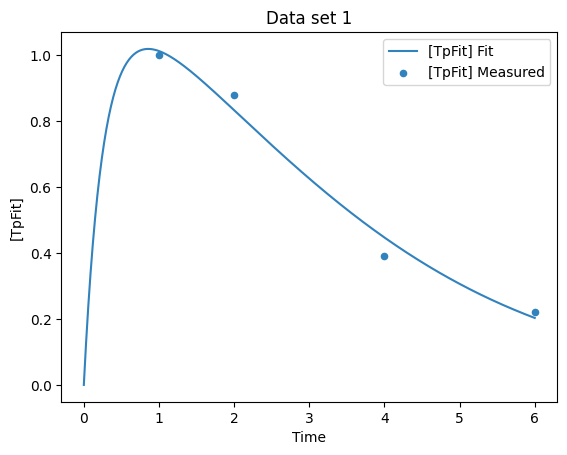

In [14]:
plot_per_experiment();


The measurements fall from 1.0 to 0.22, and the root mean square residual is about 0.04. The trajectory follows the four points. That is a statement about the residuals. The correlation matrix and the Fisher information matrix answer a separate question: whether the two rate constants are each pinned down.

## Correlation matrix

`get_correlation_matrix` returns the parameter correlation matrix at the current solution. The diagonal is 1. An off-diagonal entry near +1 or −1 means a change in one parameter can be compensated by a change in the other, leaving the weighted residuals almost unchanged.


In [15]:
correlation = get_correlation_matrix()
correlation


,'(v1).k','(v2).k1'
'(v1).k',1,0.980734
'(v2).k1',0.980734,1


The correlation between `(v1).k` and `(v2).k1` is about 0.98. The data constrain the two rate constants as a pair. A marginal standard deviation of about 24% is the uncertainty of one constant while the other is held at its estimate; once both are free to move together, a much larger coordinated change still fits. Correlations above roughly 0.9 are a sign that the corresponding parameters are only weakly separable.

## Fisher information matrix

`get_fisher_information_matrix` returns the Fisher information matrix of the fit. With `scaled=True`, the default, each parameter is scaled by its value. An entry then describes information about a relative change, and parameters of different magnitude can be compared. `scaled=False` returns the matrix in the original parameter units.

The matrix is the curvature of the objective at the solution. A large diagonal entry means the weighted residuals respond strongly to that parameter. A large off-diagonal entry means the two parameters trade off. The unscaled matrix is the one that connects to the reported standard deviations: if `F` is that matrix and `sd` is the residual standard deviation,

covariance ≈ sd² · F⁻¹.


In [16]:
fim_scaled = get_fisher_information_matrix(scaled=True)
fim_scaled


,'(v1).k','(v2).k1'
'(v1).k',1.24377,-1.28974
'(v2).k1',-1.28974,1.39047


In [17]:
fim = get_fisher_information_matrix(scaled=False)
fim


,'(v1).k','(v2).k1'
'(v1).k',0.241811,-0.399017
'(v2).k1',-0.399017,0.684549


Both matrices have a positive diagonal and a negative off-diagonal of comparable size. The data carry information about both rates, and that information is coupled. Compare parameters on the scaled matrix. Recover standard deviations from the unscaled matrix, which the last section does numerically.

## Eigenvalues and eigenvectors

`get_fisher_information_eigenvalues` and `get_fisher_information_eigenvectors` diagonalize the Fisher matrix. The eigenvalue and the eigenvector that share an index belong together. A large eigenvalue is a direction the data determine tightly. A small eigenvalue is a direction they barely determine. The ratio of the largest eigenvalue to the smallest is the condition number of the matrix.

The scaled decomposition is the one to read when comparing directions, because it is dimensionless. `scaled=False` repeats the decomposition for the unscaled matrix.


In [18]:
eigenvalues_scaled = get_fisher_information_eigenvalues(scaled=True)
eigenvalues_scaled


,1
1,0.0252965
2,2.60895


In [19]:
eigenvectors_scaled = get_fisher_information_eigenvectors(scaled=True)
eigenvectors_scaled


,'(v1).k','(v2).k1'
1,-0.726904,-0.686739
2,-0.686739,0.726904


In [20]:
get_fisher_information_eigenvalues(scaled=False)


,1
1,0.00687001
2,0.91949


In [21]:
get_fisher_information_eigenvectors(scaled=False)


,'(v1).k','(v2).k1'
1,-0.861722,-0.507381
2,-0.507381,0.861722


In [22]:
spectrum = eigenvalues_scaled.iloc[:, 0].to_numpy(dtype=float)
condition = spectrum.max() / spectrum.min()
pd.Series({
    'smallest eigenvalue': spectrum.min(),
    'largest eigenvalue': spectrum.max(),
    'condition number': condition,
    'uncertainty ratio': np.sqrt(condition),
})


smallest eigenvalue   0.0252965
largest eigenvalue      2.60895
condition number        103.135
uncertainty ratio       10.1555
dtype: float64

The scaled eigenvalues differ by about two orders of magnitude, and the condition number is about 100. The square root of that ratio, about 10, is the factor between the uncertainty along the poorly determined direction and the uncertainty along the well determined one.

The eigenvector of the small eigenvalue has two components of the same sign and almost the same size. It is the direction in which both rate constants change together, so the ratio `(v1).k / (v2).k1` stays nearly constant. Along a balance of the activation and the back-reaction, `Tp` depends on that ratio, and a common change of both rates is only weakly visible in `[TpFit]`. The eigenvector of the large eigenvalue has components of opposite sign. That direction changes the ratio, and the measurements of `Tp` respond to it. The time course identifies the balance of the two reactions much more tightly than it identifies their overall speed.

The unscaled eigenvectors describe the same split in the original parameter units. Their components differ in size because `(v1).k` and `(v2).k1` have different values. The scaled vectors are the comparison of relative changes.

## The statistic and the matrices are one approximation

The standard deviations and the correlation matrix are this curvature, written back in parameter units. With `F` the unscaled Fisher matrix:

covariance = sd² · F⁻¹

The square root of the diagonal is the standard deviation reported in the fit statistic. Rescaling that covariance to a unit diagonal produces the correlation matrix.


In [23]:
covariance = stat['sd'] ** 2 * np.linalg.inv(fim.to_numpy(dtype=float))
marginal_std = np.sqrt(np.diag(covariance))
reported_std = np.array([item['std_dev'] for item in stat['parameters']])

scale = np.sqrt(np.diag(covariance))
correlation_from_fim = covariance / np.outer(scale, scale)

print('standard deviation from sd^2 * F^{-1}:', marginal_std)
print('standard deviation from the fit statistic:', reported_std)
pd.DataFrame(
    correlation_from_fim,
    index=fim.index,
    columns=fim.columns,
)


standard deviation from sd^2 * F^{-1}: [0.56571926 0.33623009]
standard deviation from the fit statistic: [0.56571926 0.33623009]


,'(v1).k','(v2).k1'
'(v1).k',1,0.980734
'(v2).k1',0.980734,1


The two routes agree. Taken together, the tables describe the stored solution as follows.

- The simulation reproduces the four `[TpFit]` measurements. The root mean square residual is about 0.04, and the mean residual is about zero.
- The gradients are close to zero, so the stored values are a stationary point of the objective.
- `(v1).k` and `(v2).k1` are strongly correlated. The data determine the combination in which the two rates move against each other, and they leave a common change of both rates much less determined. The coefficients of variation near 24% are the marginal uncertainties of that local approximation.

The Fisher matrix is a local, quadratic summary around the solution. When an eigenvalue is many orders of magnitude below the others, or a correlation is essentially ±1, the parameters are practically non-identifiable along that direction, and a profile likelihood is what maps the objective away from the optimum. That analysis is set up for this same model in [Profile likelihood](Profile_likelihood.ipynb).
